<a href="https://colab.research.google.com/github/joao-araujoo/calculo-numerico/blob/main/gauss_seidel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Método de Gauss-Seidel
Cálculo Numérico - Profa. Raquel Lobosco

João Araujo

## Questão 5

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

A = np.array([[10, -1, 2],
              [-1, 11, -1],
              [2, -1, 10]], dtype=float)
b = np.array([6, 22, -10], dtype=float)


def gauss_seidel(A, b, x0, tol=1e-5, max_iter=100):
    n = len(b)
    x = np.array(x0, dtype=float)
    historico = [(0, *x, np.nan)]

    for k in range(1, max_iter + 1):
        x_ant = x.copy()
        for i in range(n):
            soma1 = np.dot(A[i, :i], x[:i])
            soma2 = np.dot(A[i, i+1:], x_ant[i+1:])
            x[i] = (b[i] - soma1 - soma2) / A[i, i]

        erro = np.max(np.abs(x - x_ant))
        historico.append((k, *x, erro))

        if erro < tol:
            break

    return x, k, historico


sol, n_iter, hist = gauss_seidel(A, b, [0, 0, 0])

print("Número de iterações:", n_iter)
print("Solução aproximada:", sol)

Número de iterações: 6
Solução aproximada: [ 1.00000003  1.99999998 -1.00000001]


## Questão 6

In [2]:
tabela = pd.DataFrame(hist, columns=["k", "x(k)", "y(k)", "z(k)", "erro"])
tabela

,k,x(k),y(k),z(k),erro
0,0,0.000000,0.000000,0.000000,NaN
1,1,0.600000,2.054545,-0.914545,2.054545
2,2,0.988364,2.006711,-0.997002,0.388364
3,3,1.000071,2.000279,-0.999986,0.011708
4,4,1.000025,2.000004,-1.000005,0.000276
5,5,1.000001,2.000000,-1.000000,0.000024
6,6,1.000000,2.000000,-1.000000,0.000001


## Questão 7

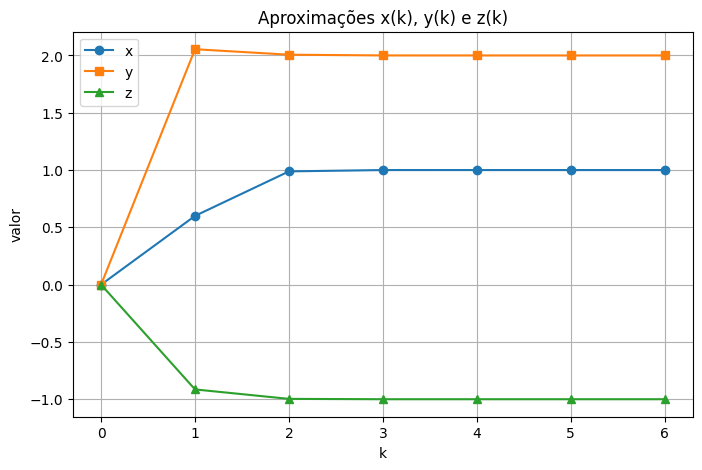

In [3]:
plt.figure(figsize=(8, 5))
plt.plot(tabela["k"], tabela["x(k)"], "o-", label="x")
plt.plot(tabela["k"], tabela["y(k)"], "s-", label="y")
plt.plot(tabela["k"], tabela["z(k)"], "^-", label="z")
plt.xlabel("k")
plt.ylabel("valor")
plt.title("Aproximações x(k), y(k) e z(k)")
plt.legend()
plt.grid()
plt.savefig("grafico_a.png", dpi=200)
plt.show()

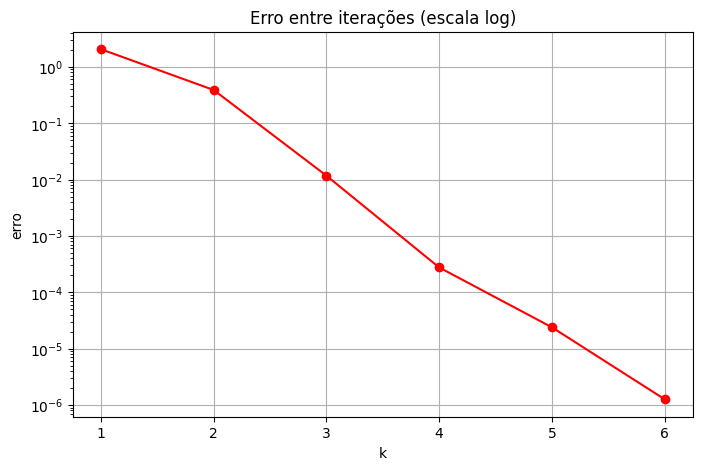

In [4]:
plt.figure(figsize=(8, 5))
plt.semilogy(tabela["k"][1:], tabela["erro"][1:], "o-", color="red")
plt.xlabel("k")
plt.ylabel("erro")
plt.title("Erro entre iterações (escala log)")
plt.grid()
plt.savefig("grafico_b.png", dpi=200)
plt.show()